# Machine Failure Prediction — AI4I 2020

**Goal:** predict whether a milling machine will fail from its process readings, so maintenance can be scheduled before the failure.

Dataset: [AI4I 2020 Predictive Maintenance (UCI)](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    mutual_info_score,
    precision_score,
    recall_score,
    confusion_matrix,
)
from xgboost import XGBClassifier

from features import load_raw, add_features, TARGET

SEED = 42

## 1. Data loading & cleaning

In [33]:
raw = pd.read_csv('data/ai4i2020.csv')
raw.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


TODO:
- Shape, dtypes, `describe()`, missing values, duplicates
- Explain why `UDI`, `Product ID` and `TWF/HDF/PWF/OSF/RNF` are dropped (IDs + target leakage)

In [34]:
df = load_raw('data/ai4i2020.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   type                 10000 non-null  str    
 1   air_temperature      10000 non-null  float64
 2   process_temperature  10000 non-null  float64
 3   rotational_speed     10000 non-null  int64  
 4   torque               10000 non-null  float64
 5   tool_wear            10000 non-null  int64  
 6   machine_failure      10000 non-null  int64  
dtypes: float64(3), int64(3), str(1)
memory usage: 547.0 KB


In [35]:
print("""10,000 rows and 14 columns, each row is one reading from a milling machine.
I dropped UDI and Product ID because they're just IDs.
I also dropped TWF/HDF/PWF/OSF/RNF: they say how the machine failed, which is basically the answer
(330 of the 339 failures have one of them set), so keeping them would be leakage.""")
modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
print(raw.shape)
pd.crosstab(raw[modes].max(axis=1), raw['Machine failure'], rownames=['any failure mode'], colnames=['Machine failure'])

10,000 rows and 14 columns, each row is one reading from a milling machine.
I dropped UDI and Product ID because they're just IDs.
I also dropped TWF/HDF/PWF/OSF/RNF: they say how the machine failed, which is basically the answer
(330 of the 339 failures have one of them set), so keeping them would be leakage.
(10000, 14)


Machine failure,0,1
any failure mode,,
0,9643,9
1,18,330


In [36]:
display(df.describe().T)
print(df.isnull().sum())
print('duplicates:', df.duplicated().sum())
print("""No missing values, no duplicates, and all the ranges look realistic, so there's nothing to clean.""")

,count,mean,std,min,25%,50%,75%,max
air_temperature,10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
process_temperature,10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
rotational_speed,10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
torque,10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
tool_wear,10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0
machine_failure,10000.0,0.03390,0.180981,0.0,0.0,0.0,0.0,1.0


type                   0
air_temperature        0
process_temperature    0
rotational_speed       0
torque                 0
tool_wear              0
machine_failure        0
dtype: int64
duplicates: 0
No missing values, no duplicates, and all the ranges look realistic, so there's nothing to clean.


## 2. EDA

### 2.1 Target variable
TODO: failure rate, bar plot. Comment on the imbalance and what it means for the metric (why not accuracy?).

machine_failure
0    9661
1     339
Name: count, dtype: int64
failure rate: 0.0339
Only 339 of 10,000 machines fail (3.4%).
A model that always says "no failure" would be 96.6% accurate and still useless,
so accuracy is out. I need a metric that focuses on catching the failures.


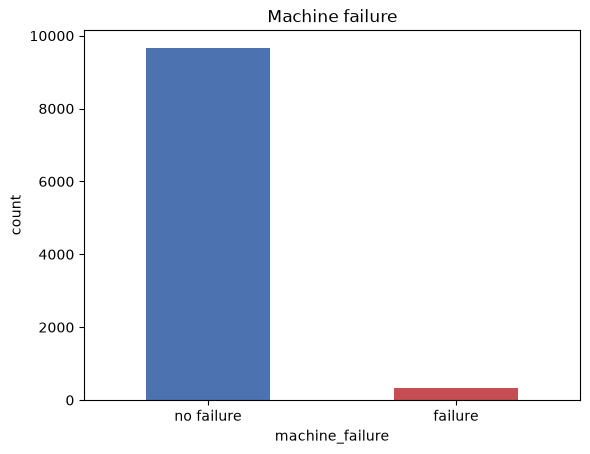

In [37]:
print(df[TARGET].value_counts())
print(f'failure rate: {df[TARGET].mean():.4f}')

ax = df[TARGET].value_counts().sort_index().plot(kind='bar', color=['#4c72b0', '#c44e52'])
ax.set_xticklabels(['no failure', 'failure'], rotation=0)
ax.set_ylabel('count')
ax.set_title('Machine failure');
print("""Only 339 of 10,000 machines fail (3.4%).
A model that always says "no failure" would be 96.6% accurate and still useless,
so accuracy is out. I need a metric that focuses on catching the failures.""")

### 2.2 Numerical features
TODO: histograms, boxplots split by `machine_failure`, ranges of values, correlation heatmap.

,min,max,mean,std
air_temperature,295.3,304.5,300.00493,2.000259
process_temperature,305.7,313.8,310.00556,1.483734
rotational_speed,1168.0,2886.0,1538.77610,179.284096
torque,3.8,76.6,39.98691,9.968934
tool_wear,0.0,253.0,107.95100,63.654147


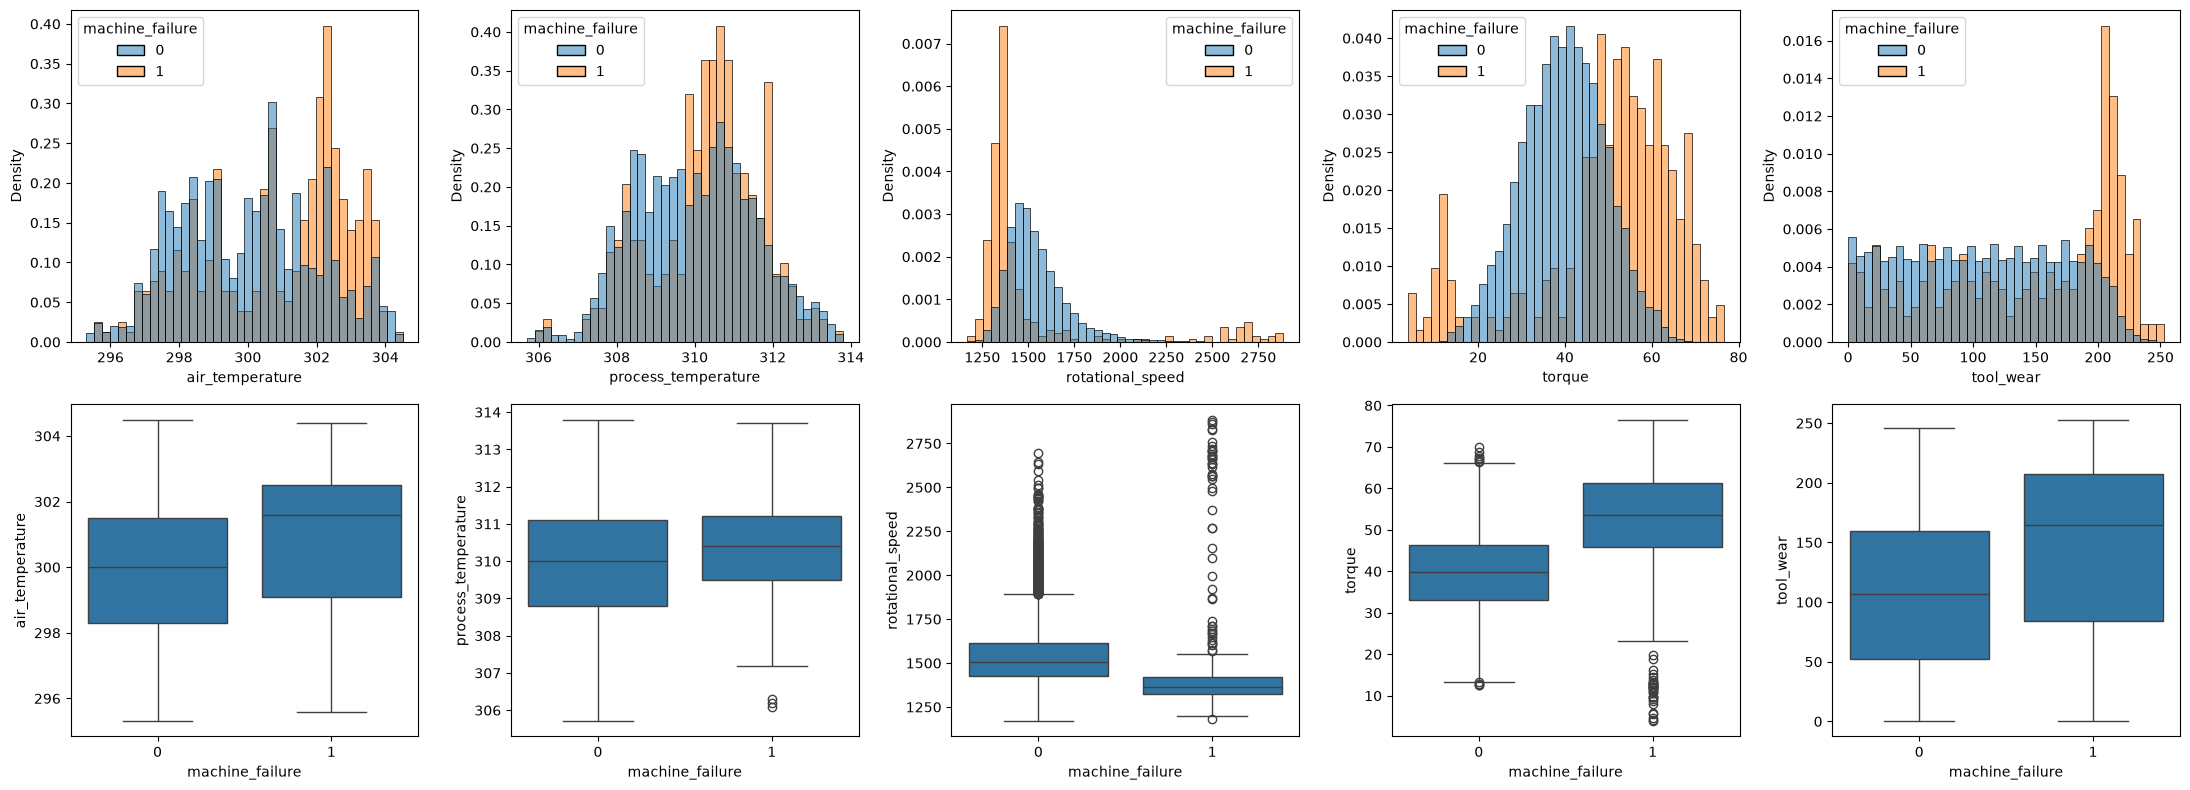

- Failures show up with high torque + low speed, and when tool wear goes past ~200 min.
- Air and process temperature move together (0.88), same for speed and torque (-0.88).
- Nothing correlates strongly with failure on its own (max 0.19), so the patterns aren't linear.


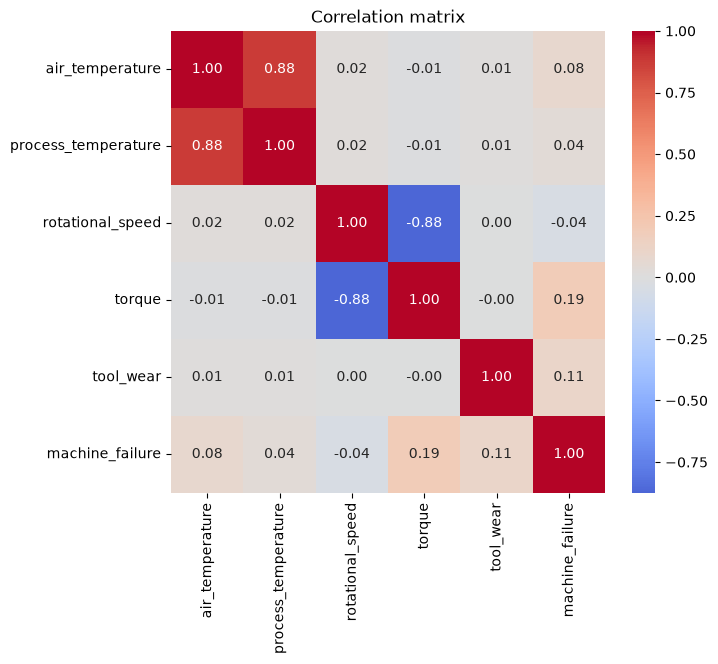

In [38]:
numerical = ['air_temperature', 'process_temperature', 'rotational_speed', 'torque', 'tool_wear']
display(df[numerical].agg(['min', 'max', 'mean', 'std']).T)

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for i, col in enumerate(numerical):
    sns.histplot(data=df, x=col, hue=TARGET, stat='density', common_norm=False, bins=40, ax=axes[0, i])
    sns.boxplot(data=df, x=TARGET, y=col, ax=axes[1, i])
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
sns.heatmap(df[numerical + [TARGET]].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix');
print("""- Failures show up with high torque + low speed, and when tool wear goes past ~200 min.
- Air and process temperature move together (0.88), same for speed and torque (-0.88).
- Nothing correlates strongly with failure on its own (max 0.19), so the patterns aren't linear.""")

### 2.3 Categorical feature (`type`)
TODO: failure rate per L/M/H, risk ratio.

,mean,count,diff,risk
type,,,,
H,0.020937,1003,-0.012963,0.617616
L,0.039167,6000,0.005267,1.155359
M,0.027694,2997,-0.006206,0.816943


L products fail the most (3.9%, 1.16x the average) and H the least (2.1%, 0.62x).
The difference is small but real, so I'm keeping type.


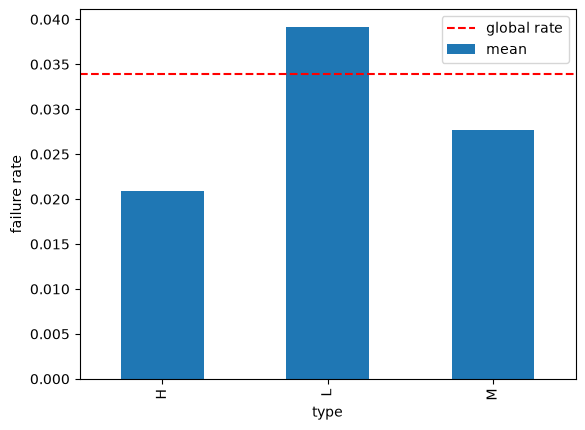

In [39]:
global_rate = df[TARGET].mean()
type_stats = df.groupby('type')[TARGET].agg(['mean', 'count'])
type_stats['diff'] = type_stats['mean'] - global_rate
type_stats['risk'] = type_stats['mean'] / global_rate
display(type_stats)

ax = type_stats['mean'].plot(kind='bar')
ax.axhline(global_rate, color='red', linestyle='--', label='global rate')
ax.set_ylabel('failure rate')
ax.legend();
print("""L products fail the most (3.9%, 1.16x the average) and H the least (2.1%, 0.62x).
The difference is small but real, so I'm keeping type.""")

### 2.4 Feature engineering
TODO: check that `temp_diff`, `power`, `strain` (see `features.py`) separate failures better than the raw columns. Plot failure rate vs each.

torque                 0.770237
rotational_speed       0.766687
power                  0.745652
strain                 0.704441
temp_diff              0.662363
tool_wear              0.662112
air_temperature        0.632736
process_temperature    0.563706
dtype: float64

- temp_diff: when the gap drops below ~8.8 K, the failure rate jumps to 11.8% (vs ~2% otherwise).
- power: U-shaped, failures spike at both very low and very high power.
- strain: a worn tool under high torque fails 15.4% of the time (top decile).
All three line up with real failure types, so I'm keeping them. They prove their worth in section 5.


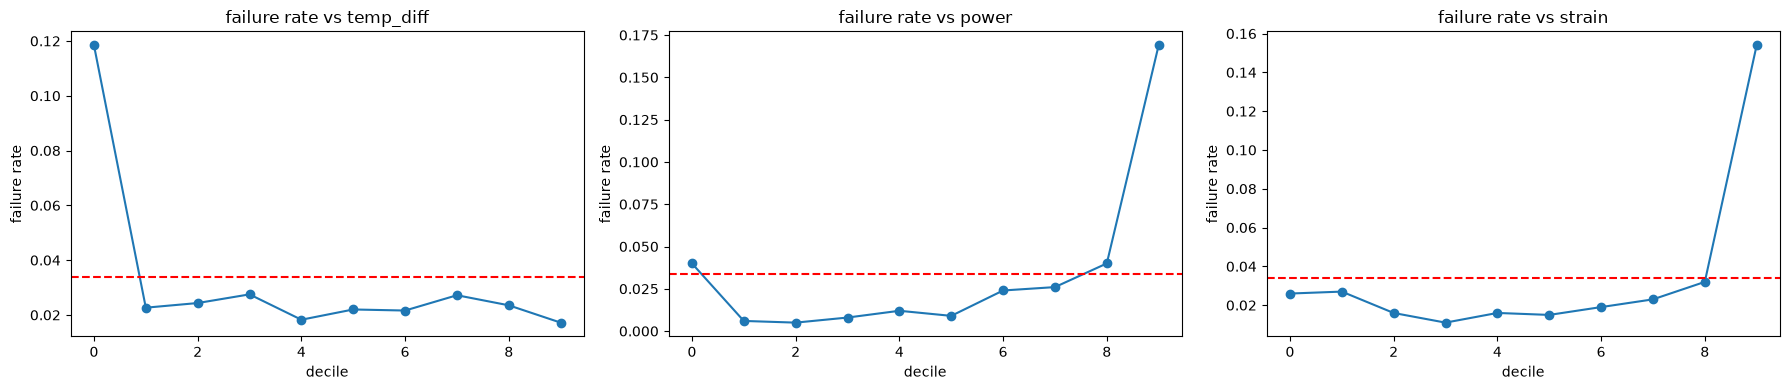

In [40]:
df = add_features(df)
engineered = ['temp_diff', 'power', 'strain']

def single_feature_auc(series, y):
    auc = roc_auc_score(y, series)
    return max(auc, 1 - auc)

auc_table = pd.Series(
    {c: single_feature_auc(df[c], df[TARGET]) for c in numerical + engineered}
).sort_values(ascending=False)
display(auc_table)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, engineered):
    rate = df.groupby(pd.qcut(df[col], q=10, duplicates='drop'), observed=True)[TARGET].mean()
    ax.plot(range(len(rate)), rate.values, marker='o')
    ax.axhline(global_rate, color='red', linestyle='--')
    ax.set_xlabel('decile')
    ax.set_ylabel('failure rate')
    ax.set_title(f'failure rate vs {col}')
plt.tight_layout()
print("""- temp_diff: when the gap drops below ~8.8 K, the failure rate jumps to 11.8% (vs ~2% otherwise).
- power: U-shaped, failures spike at both very low and very high power.
- strain: a worn tool under high torque fails 15.4% of the time (top decile).
All three line up with real failure types, so I'm keeping them. They prove their worth in section 5.""")

### 2.5 Feature importance
TODO: mutual information for `type`, correlation / ROC AUC per numerical feature, and later the tree model's `feature_importances_`.

In [41]:
print("""type barely matters (MI = 0.0007). Correlations are all under 0.2 even though some AUCs reach 0.77,
so the relationships aren't linear and tree models should do better here.""")
print('MI(type, target):', mutual_info_score(df['type'], df[TARGET]))
pd.DataFrame({
    'corr': df[numerical + engineered].corrwith(df[TARGET]),
    'roc_auc': auc_table,
}).sort_values('roc_auc', ascending=False)

type barely matters (MI = 0.0007). Correlations are all under 0.2 even though some AUCs reach 0.77,
so the relationships aren't linear and tree models should do better here.
MI(type, target): 0.0007268221729692104


,corr,roc_auc
torque,0.191321,0.770237
rotational_speed,-0.044188,0.766687
power,0.176039,0.745652
strain,0.190427,0.704441
temp_diff,-0.111676,0.662363
tool_wear,0.105448,0.662112
air_temperature,0.082556,0.632736
process_temperature,0.035946,0.563706


## 3. Validation framework

In [42]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df[TARGET])
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=SEED, stratify=df_full_train[TARGET])

y_train = df_train.pop(TARGET).values
y_val = df_val.pop(TARGET).values
y_test = df_test.pop(TARGET).values

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))

len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

TODO: choose the main metric (ROC AUC vs PR AUC) and justify it.

In [43]:
def evaluate(model):
    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_val)[:, 1]
    return average_precision_score(y_val, y_pred), roc_auc_score(y_val, y_pred)

best = {}
print("""I'm going with PR AUC as the main metric. With only 3.4% failures, ROC AUC looks good too easily
because of all the easy "no failure" rows. PR AUC only cares about catching failures and not raising
too many false alarms. There are only 68 failures in validation, so small differences are just noise.""")

I'm going with PR AUC as the main metric. With only 3.4% failures, ROC AUC looks good too easily
because of all the easy "no failure" rows. PR AUC only cares about catching failures and not raising
too many false alarms. There are only 68 failures in validation, so small differences are just noise.


## 4. Models
Train each, tune its parameters on the validation set, record the best score.

### 4.1 Logistic regression
TODO: scale features? tune `C`, try `class_weight='balanced'`.

In [44]:
scores = []
for C in [0.01, 0.1, 1, 10, 100]:
    for cw in [None, 'balanced']:
        model = make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight=cw, max_iter=5000))
        scores.append((C, str(cw), *evaluate(model)))

df_lr = pd.DataFrame(scores, columns=['C', 'class_weight', 'pr_auc', 'roc_auc']).sort_values('pr_auc', ascending=False)
best['Logistic regression'] = df_lr.iloc[0]
display(df_lr.head())
print("""Best: C=1, no class weight -> PR AUC 0.47. I scaled the features since rpm and Kelvin are on very
different scales. class_weight='balanced' didn't help. A linear model just can't capture these patterns.""")

,C,class_weight,pr_auc,roc_auc
4,1.0,None,0.472880,0.897980
8,100.0,None,0.469442,0.909405
6,10.0,None,0.469052,0.908309
3,0.1,balanced,0.439474,0.903224
5,1.0,balanced,0.434798,0.920762


Best: C=1, no class weight -> PR AUC 0.47. I scaled the features since rpm and Kelvin are on very
different scales. class_weight='balanced' didn't help. A linear model just can't capture these patterns.


### 4.2 Decision tree
TODO: tune `max_depth`, `min_samples_leaf`.

In [45]:
scores = []
for d in [3, 4, 5, 6, 7, 8, 10, 15, None]:
    for leaf in [1, 5, 10, 20, 50]:
        model = DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=SEED)
        scores.append((d, leaf, *evaluate(model)))

df_dt = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'pr_auc', 'roc_auc']).sort_values('pr_auc', ascending=False)
best['Decision tree'] = df_dt.iloc[0]
display(df_dt.head())
print("""Best: max_depth=8, min_samples_leaf=10 -> PR AUC 0.86. A huge jump from logistic regression.
Trees with no limits overfit.""")

,max_depth,min_samples_leaf,pr_auc,roc_auc
27,8.0,10,0.861427,0.982116
22,7.0,10,0.860766,0.981161
17,6.0,10,0.857187,0.981610
23,7.0,20,0.855703,0.980754
18,6.0,20,0.854809,0.981405


Best: max_depth=8, min_samples_leaf=10 -> PR AUC 0.86. A huge jump from logistic regression.
Trees with no limits overfit.


### 4.3 Random forest
TODO: tune `n_estimators`, `max_depth`, `min_samples_leaf`.

In [46]:
scores = []
for n in [100, 200, 300]:
    for d in [5, 10, 15, None]:
        for leaf in [1, 3, 5]:
            model = RandomForestClassifier(n_estimators=n, max_depth=d, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1)
            scores.append((n, d, leaf, *evaluate(model)))

df_rf = pd.DataFrame(scores, columns=['n_estimators', 'max_depth', 'min_samples_leaf', 'pr_auc', 'roc_auc']).sort_values('pr_auc', ascending=False)
best['Random forest'] = df_rf.iloc[0]
display(df_rf.head())
print("""Best: 300 trees, max_depth=10, min_samples_leaf=3 -> PR AUC 0.865.
Depth 5 is too shallow, but anything from 10 up scores about the same, so it's not picky about settings.""")

,n_estimators,max_depth,min_samples_leaf,pr_auc,roc_auc
28,300,10.0,3,0.864686,0.977994
31,300,15.0,3,0.864553,0.975125
34,300,NaN,3,0.863252,0.975608
27,300,10.0,1,0.863001,0.979144
16,200,10.0,3,0.862504,0.978573


Best: 300 trees, max_depth=10, min_samples_leaf=3 -> PR AUC 0.865.
Depth 5 is too shallow, but anything from 10 up scores about the same, so it's not picky about settings.


### 4.4 XGBoost
TODO: tune `eta`, `max_depth`, `min_child_weight`, try `scale_pos_weight`.

In [47]:
scores = []
for n in [100, 200, 300]:
    for eta in [0.05, 0.1, 0.3]:
        for d in [3, 4, 6]:
            for mcw in [1, 5]:
                model = XGBClassifier(n_estimators=n, learning_rate=eta, max_depth=d, min_child_weight=mcw,
                                      eval_metric='aucpr', random_state=SEED, n_jobs=-1)
                scores.append((n, eta, d, mcw, *evaluate(model)))

df_xgb = pd.DataFrame(scores, columns=['n_estimators', 'eta', 'max_depth', 'min_child_weight', 'pr_auc', 'roc_auc']).sort_values('pr_auc', ascending=False)
xgb_best = df_xgb.iloc[0]
best['XGBoost'] = xgb_best
display(df_xgb.head())

for spw in [1, 3, 5, 10, 28]:
    model = XGBClassifier(n_estimators=int(xgb_best.n_estimators), learning_rate=xgb_best.eta,
                          max_depth=int(xgb_best.max_depth), min_child_weight=int(xgb_best.min_child_weight),
                          scale_pos_weight=spw, eval_metric='aucpr', random_state=SEED, n_jobs=-1)
    print('scale_pos_weight', spw, evaluate(model))
print("""Best: 100 rounds, eta=0.05, max_depth=3 -> PR AUC 0.85. More rounds started to overfit.
scale_pos_weight made it slightly worse, so I'll handle the imbalance with the threshold instead.""")

,n_estimators,eta,max_depth,min_child_weight,pr_auc,roc_auc
0,100,0.05,3,1,0.851521,0.984967
2,100,0.05,4,1,0.850805,0.981835
4,100,0.05,6,1,0.847430,0.978006
8,100,0.10,4,1,0.844840,0.975821
20,200,0.05,4,1,0.842198,0.976522


scale_pos_weight 1 (0.8515209641870451, 0.9849668128120812)
scale_pos_weight 3 (0.8438533914450411, 0.9845748081841432)
scale_pos_weight 5 (0.8440367676152548, 0.9848526367068567)
scale_pos_weight 10 (0.8460270797871742, 0.9849287541103398)
scale_pos_weight 28 (0.8346443565711756, 0.9842322798684692)
Best: 100 rounds, eta=0.05, max_depth=3 -> PR AUC 0.85. More rounds started to overfit.
scale_pos_weight made it slightly worse, so I'll handle the imbalance with the threshold instead.


## 5. Model selection
TODO: comparison table of the best validation score per model. Pick one and explain why.

In [48]:
display(pd.DataFrame({k: {'val_pr_auc': v['pr_auc'], 'val_roc_auc': v['roc_auc']} for k, v in best.items()}).T)

rf_params = dict(n_estimators=300, max_depth=10, min_samples_leaf=3, random_state=SEED, n_jobs=-1)
xgb_params = dict(n_estimators=100, learning_rate=0.05, max_depth=3, min_child_weight=1,
                  eval_metric='aucpr', random_state=SEED, n_jobs=-1)

y_full_train = df_full_train[TARGET].values
raw_features = ['type'] + numerical

def cross_validate(make_model, columns):
    records = df_full_train[columns].to_dict(orient='records')
    out = []
    for tr, va in StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(records, y_full_train):
        fold_dv = DictVectorizer(sparse=False)
        X_tr = fold_dv.fit_transform([records[i] for i in tr])
        X_va = fold_dv.transform([records[i] for i in va])
        model = make_model().fit(X_tr, y_full_train[tr])
        out.append(average_precision_score(y_full_train[va], model.predict_proba(X_va)[:, 1]))
    return np.mean(out), np.std(out)

display(pd.DataFrame({
    'Random forest': cross_validate(lambda: RandomForestClassifier(**rf_params), raw_features + engineered),
    'XGBoost': cross_validate(lambda: XGBClassifier(**xgb_params), raw_features + engineered),
    'RF raw features only': cross_validate(lambda: RandomForestClassifier(**rf_params), raw_features),
    'XGB raw features only': cross_validate(lambda: XGBClassifier(**xgb_params), raw_features),
}, index=['cv_pr_auc', 'std']).T)
print("""Random forest and XGBoost were close on validation, so I double-checked with 5-fold CV.
Random forest wins (0.90 vs 0.88) and is easier to tune, so that's my pick.
Without temp_diff, power and strain it drops to 0.76, so the engineered features really pay off.""")

,val_pr_auc,val_roc_auc
Logistic regression,0.472880,0.897980
Decision tree,0.861427,0.982116
Random forest,0.864686,0.977994
XGBoost,0.851521,0.984967


,cv_pr_auc,std
Random forest,0.900230,0.024260
XGBoost,0.881446,0.027025
RF raw features only,0.761020,0.017974
XGB raw features only,0.748057,0.033310


Random forest and XGBoost were close on validation, so I double-checked with 5-fold CV.
Random forest wins (0.90 vs 0.88) and is easier to tune, so that's my pick.
Without temp_diff, power and strain it drops to 0.76, so the engineered features really pay off.


## 6. Final model
TODO: retrain on train+val, evaluate once on test. Pick the decision threshold from the precision-recall curve (copy it into `predict.py`). Copy the final params into `train.py`.

threshold=0.24  precision=0.869  recall=0.779


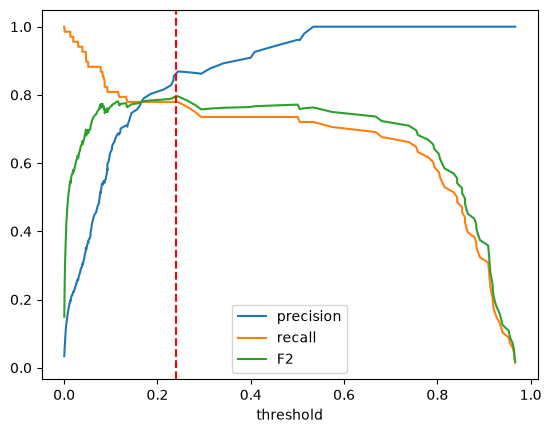

test PR AUC : 0.8987
test ROC AUC: 0.9817
precision   : 0.879
recall      : 0.853
[[1924    8]
 [  10   58]]


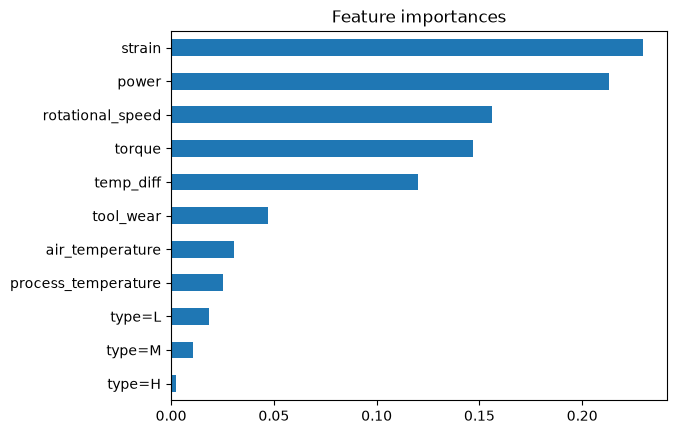

Missing a failure is worse than a false alarm, so I picked the threshold with F2 (recall counts double).
That gives 0.24. On the test set the model catches 58 of 68 failures with only 8 false alarms (PR AUC 0.90).
strain and power are the top two features, both ones I engineered.


In [49]:
rf_val = RandomForestClassifier(**rf_params).fit(X_train, y_train)
y_val_pred = rf_val.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_val, y_val_pred)
precision, recall = precision[:-1], recall[:-1]
f2 = 5 * precision * recall / (4 * precision + recall + 1e-12)
i = np.argmax(f2)
threshold = round(float(thresholds[i]), 2)
print(f'threshold={threshold}  precision={precision[i]:.3f}  recall={recall[i]:.3f}')

plt.plot(thresholds, precision, label='precision')
plt.plot(thresholds, recall, label='recall')
plt.plot(thresholds, f2, label='F2')
plt.axvline(threshold, color='red', linestyle='--')
plt.xlabel('threshold')
plt.legend()
plt.show()

dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(df_full_train.drop(columns=[TARGET]).to_dict(orient='records'))
X_test = dv_final.transform(df_test.to_dict(orient='records'))

final_model = RandomForestClassifier(**rf_params).fit(X_full_train, y_full_train)
y_test_pred = final_model.predict_proba(X_test)[:, 1]
y_test_label = (y_test_pred >= threshold).astype(int)

print('test PR AUC :', round(average_precision_score(y_test, y_test_pred), 4))
print('test ROC AUC:', round(roc_auc_score(y_test, y_test_pred), 4))
print('precision   :', round(precision_score(y_test, y_test_label), 3))
print('recall      :', round(recall_score(y_test, y_test_label), 3))
print(confusion_matrix(y_test, y_test_label))

pd.Series(final_model.feature_importances_, index=dv_final.get_feature_names_out()).sort_values().plot(kind='barh', title='Feature importances')
plt.show()
print("""Missing a failure is worse than a false alarm, so I picked the threshold with F2 (recall counts double).
That gives 0.24. On the test set the model catches 58 of 68 failures with only 8 false alarms (PR AUC 0.90).
strain and power are the top two features, both ones I engineered.""")

## 7. Conclusions
TODO

In [50]:
print("""- Failures are rare (3.4%), so I used PR AUC and tuned the threshold instead of reweighting classes.
- The engineered features made the biggest difference: PR AUC went from 0.76 to 0.90.
- Tree models crushed logistic regression (0.86 vs 0.47) because the failure patterns aren't linear.
- Final model: random forest with threshold 0.24, catches 85% of failures at 88% precision on test.
- Limitations: the data is synthetic, the test set only has 68 failures, and random failures (RNF) can't be predicted.""")

- Failures are rare (3.4%), so I used PR AUC and tuned the threshold instead of reweighting classes.
- The engineered features made the biggest difference: PR AUC went from 0.76 to 0.90.
- Tree models crushed logistic regression (0.86 vs 0.47) because the failure patterns aren't linear.
- Final model: random forest with threshold 0.24, catches 85% of failures at 88% precision on test.
- Limitations: the data is synthetic, the test set only has 68 failures, and random failures (RNF) can't be predicted.
